# **Datos Alumno**

# * **Nombre**: Brayan Gres Juarez
# * **No control**: 23111409

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia APPLE (AAPL).**

# **0 - Preparando los datos ORIGINALES**

In [1]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [2]:
#!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

In [3]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [4]:
#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajare con Apple (AAPL)

ticker_symbol = 'AAPL'                           # selecciona las iniciales de la compañía deseada.
data = yf.download(ticker_symbol, period='5y', auto_adjust = False, multi_level_index = False)   # Se indica el período de 5 años y descargamos.
data.to_csv('historical_data.csv')               # Guardamos los datos
data.head()

[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2021-11-18,154.089462,157.869995,158.669998,153.050003,153.710007,137827700
2021-11-19,156.705307,160.550003,161.020004,156.529999,157.649994,117305600
2021-11-22,157.164047,161.020004,165.699997,161.000000,161.679993,117467900
2021-11-23,157.544724,161.410004,161.800003,159.059998,161.119995,96041900
2021-11-24,158.062027,161.940002,162.139999,159.639999,160.750000,69463600


In [5]:
#convierte a dataframe
path = 'historical_data.csv'
df = pd.read_csv(path)   #header=2 para que no tome en cuenta los 2 primeros renglones, ya que estan vacios

In [6]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1258 registros
            # 7 columnas las cuales son: Date, Adj close, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       1254 non-null   object 
 1   Adj Close  1253 non-null   float64
 2   Close      1253 non-null   float64
 3   High       1254 non-null   float64
 4   Low        1254 non-null   float64
 5   Open       1254 non-null   float64
 6   Volume     1254 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 68.7+ KB


#**B)Utiliza solamente los datos de la columna "Adj Close" en esta actividad.**

In [7]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

df = df[['Date','Adj Close']] #Seleccion de las columnas necesarias
df = df.rename(columns={'Adj Close':'y'})                    #Columna Adj Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,y
0,2021-11-18,154.089462
1,2021-11-19,156.705307
2,2021-11-22,157.164047
3,2021-11-23,157.544724
4,2021-11-24,158.062027


In [8]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Adj Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1254 non-null   datetime64[ns]
 1   y       1253 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.7 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [9]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,y
Date,
2021-11-18,154.089462
2021-11-19,156.705307
2021-11-22,157.164047
2021-11-23,157.544724
2021-11-24,158.062027


In [10]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1254, 2)

DataFrame Temporal:

(1254, 1)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [11]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-18', '2021-11-19', '2021-11-22', '2021-11-23',
               '2021-11-24', '2021-11-26', '2021-11-29', '2021-11-30',
               '2021-12-01', '2021-12-02',
               ...
               '2026-11-04', '2026-11-05', '2026-11-06', '2026-11-09',
               '2026-11-10', '2026-11-11', '2026-11-12', '2026-11-13',
               '2026-11-16', '2026-11-17'],
              dtype='datetime64[ns]', name='Date', length=1254, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [12]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

df_temp = df_temp.resample('B').asfreq()#Define frecuencia B -> frecuencia del día de actividad
df_temp.index

DatetimeIndex(['2021-11-18', '2021-11-19', '2021-11-22', '2021-11-23',
               '2021-11-24', '2021-11-25', '2021-11-26', '2021-11-29',
               '2021-11-30', '2021-12-01',
               ...
               '2026-11-04', '2026-11-05', '2026-11-06', '2026-11-09',
               '2026-11-10', '2026-11-11', '2026-11-12', '2026-11-13',
               '2026-11-16', '2026-11-17'],
              dtype='datetime64[ns]', name='Date', length=1304, freq='B')

#**C)Investiga el significado de esta columna Adj-Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Close es una columna Clave dentro de los datos historicos . El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia

##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [13]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [14]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [15]:
test.head()  #muestra registros del test

,y
Date,
2026-10-21,343.728821
2026-10-22,347.955627
2026-10-23,347.466003
2026-10-26,343.648895
2026-10-27,346.836487


In [16]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [y]
Index: []
Empty DataFrame
Columns: [y]
Index: []


In [17]:
train.shape #Entrenamiento conformado por 1285 registros y 1 columna

(1284, 1)

In [18]:
print(train.columns)

Index(['y'], dtype='object')


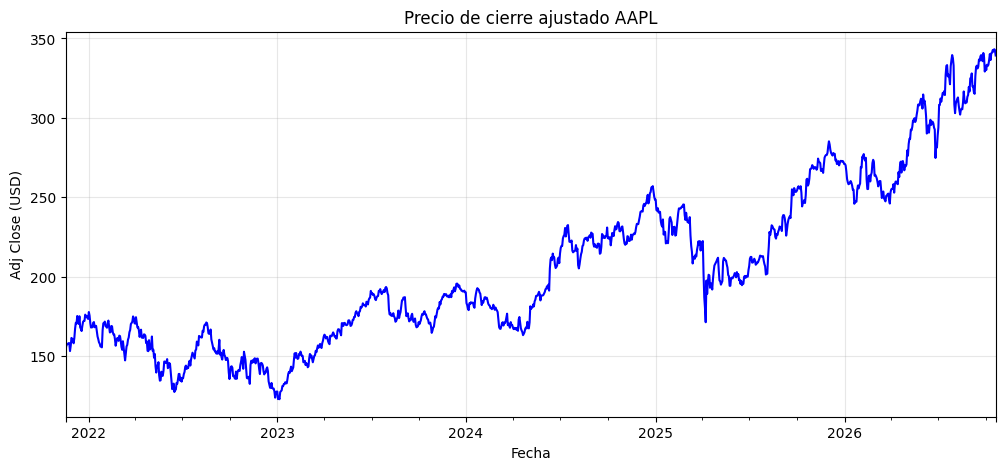

In [19]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Precio de cierre ajustado AAPL', style='-b', figsize=(12, 5))   # (mejora) tamaño más grande
plt.xlabel('Fecha')                  # (mejora) nombre de los ejes
plt.ylabel('Adj Close (USD)')
plt.grid(alpha=0.3)
plt.show()

## <font color=orange>**Escriba su Interpretación de la gráfica**</font>





## <font color=orange>**De este gráfico podemos observar:**

1. Tendencia general ascendente: entre finales de 2021 y 2026, el precio de las acciones de apple presenta una tendencia aascendente, pasando de 150 a 330 dolares   

2. Fluctuaciones en los precios: Apesar de la tendencia, se pueden observar constantes aumentos y bajas en los precios, lo que indica que no crece de manera constante.

3. Periodo de disminucion: Entre finales de 2022 y principios de 2023 se obseva una caida importante, ademas del precio mas bajo registrado en esos 5 años.

4. Crecimiento durante 2024 y 2025: En estos años se aprecia una recuperación del precio, aunque también aparecen correcciones y caídas temporales, especialmente durante 2025.

5. Valores máximos hacia 2026: En el último tramo de la gráfica, los precios alcanzan sus valores más altos del período analizado, cercanos a los 340 dólares.   



# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [20]:
test['y'].values #muestra valores del conjunto test en arreglo

array([343.7288208 , 347.95562744, 347.46600342, 343.64889526,
       346.83648682, 343.56893921, 348.64511108, 344.36834717,
       338.06314087, 331.64801025, 349.24465942, 343.90869141,
       342.11004639, 350.42373657, 348.24539185, 355.35998535,
       354.88000488, 356.26998901, 352.77999878, 352.77999878])

In [21]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)

>Esperado-real = 343, Predicción = 339.242
>Esperado-real = 347, Predicción = 343.729
>Esperado-real = 347, Predicción = 347.956
>Esperado-real = 343, Predicción = 347.466
>Esperado-real = 346, Predicción = 343.649
>Esperado-real = 343, Predicción = 346.836
>Esperado-real = 348, Predicción = 343.569
>Esperado-real = 344, Predicción = 348.645
>Esperado-real = 338, Predicción = 344.368
>Esperado-real = 331, Predicción = 338.063
>Esperado-real = 349, Predicción = 331.648
>Esperado-real = 343, Predicción = 349.245
>Esperado-real = 342, Predicción = 343.909
>Esperado-real = 350, Predicción = 342.110
>Esperado-real = 348, Predicción = 350.424
>Esperado-real = 355, Predicción = 348.245
>Esperado-real = 354, Predicción = 355.360
>Esperado-real = 356, Predicción = 354.880
>Esperado-real = 352, Predicción = 356.270
>Esperado-real = 352, Predicción = 352.780

Error-Modelo-Naive: RMSE: 5.826


----------------------------------------------------------------------------
## <font color=orange>**Interpretación**
Al comparaar los valores reales con los predcichos podemos observar que la mayorua de predicciones son cercanas, aunque presenten algunas diferencias. Con un RMSE de 5.826, nos dice que el modelo tiene un error de prediccion de aproximadamente 5.83 dolares.


-----------------------------------------------------------------------------

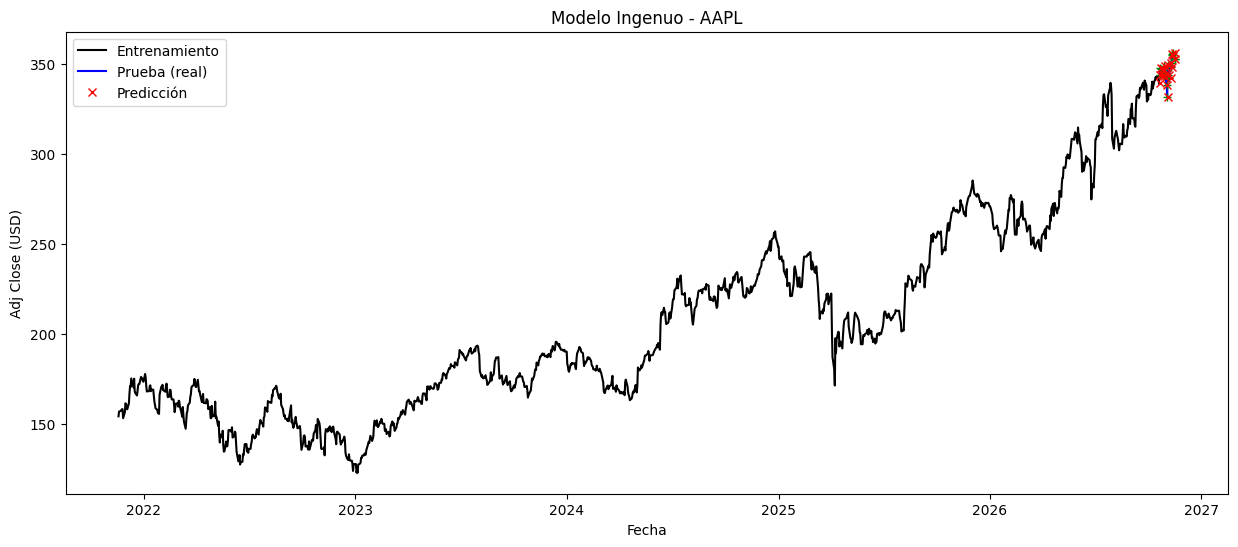

In [22]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k', label='Entrenamiento')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b', label='Prueba (real)')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr', label='Predicción')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones
plt.title('Modelo Ingenuo - AAPL')   # (mejora) título, ejes y leyenda
plt.xlabel('Fecha')
plt.ylabel('Adj Close (USD)')
plt.legend()
plt.show()

### <font color=orange>**Interpretación Gráfica.**

----------------------------------------------------------------------------
Las predicciones del modelo ingenuo se mantienen relativamente cercanas a los precios reales, aunque no coinciden completamente.

Esto ocurre porque el modelo utiliza el último precio conocido para predecir el siguiente, por lo que puede seguir los movimientos recientes, pero no anticipa cambios bruscos.

----------------------------------------------------------------------------

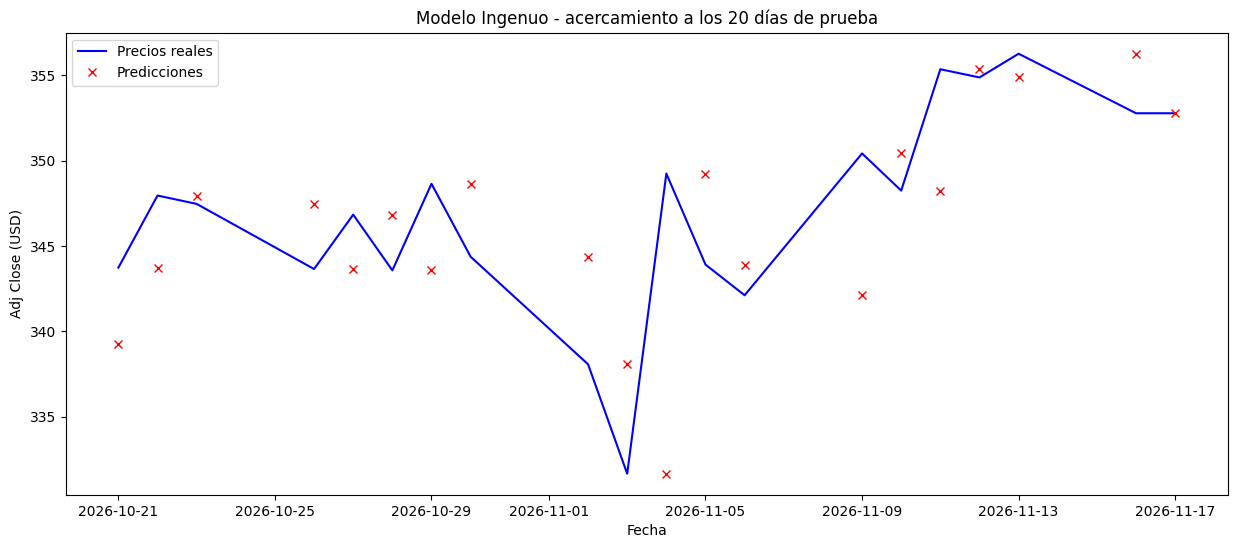

In [23]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(test['y'], '-b', label='Precios reales')
ax.plot(test.index, predictions, 'xr', label='Predicciones')

ax.set_title('Modelo Ingenuo - acercamiento a los 20 días de prueba')   # (mejora)
ax.set_xlabel('Fecha')
ax.set_ylabel('Adj Close (USD)')
ax.legend()
plt.show()

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

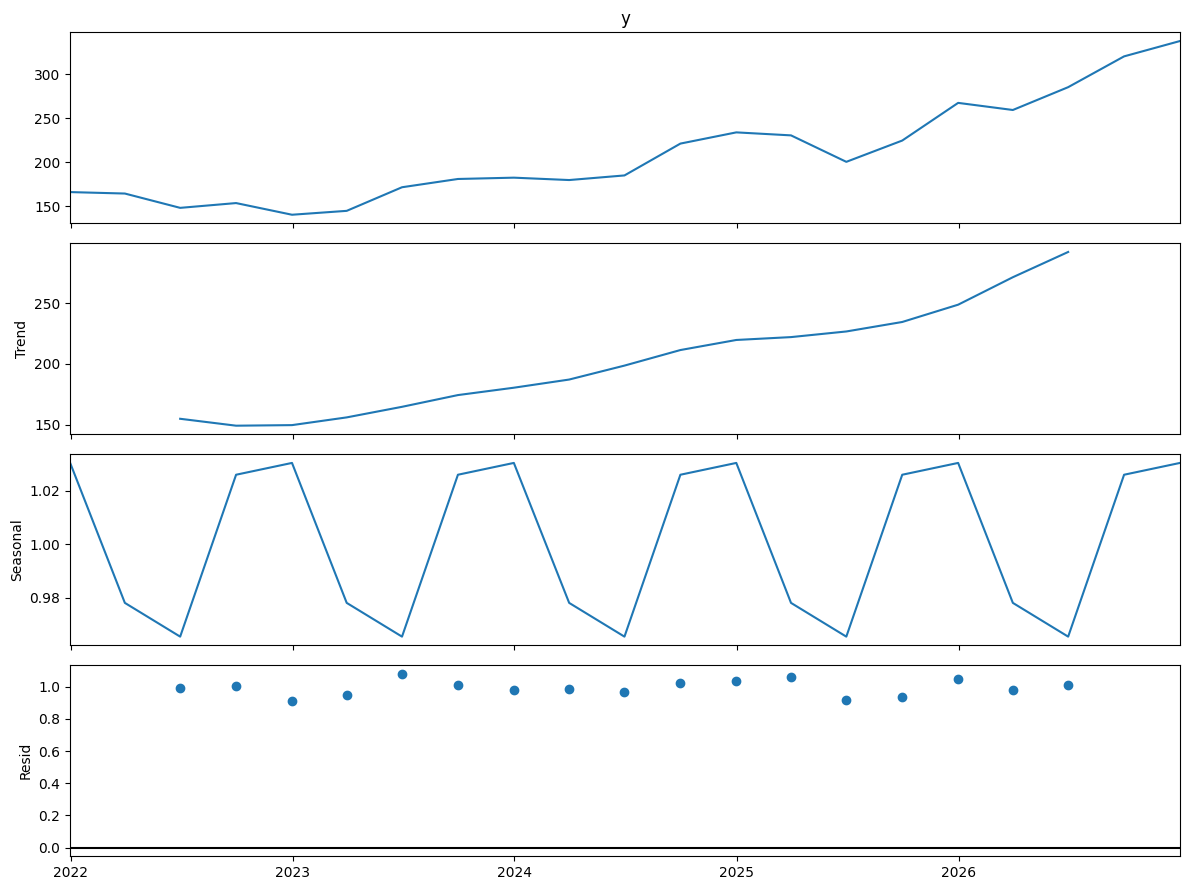

In [24]:
# Gráficos de descomposición estacional:
#parametro Q indica año
decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(12,9)   # (mejora) más grande para que no se encimen los textos
plt.tight_layout()
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

En esta gráfica nos desglosa 4 gráficas:

1. **Gráfica Original:** es el promedio trimestral del precio. Sube de unos 165 a unos 340 dólares, con bajadas en 2022 y a inicios de 2025.

2. **Tendencia (Trend):** es claramente creciente desde 2023 y se acelera en 2025-2026. Es el componente más importante de la serie.

3. **Estacional (Seasonal):** se repite el mismo patrón cada año, pero es pequeño (entre 0.96 y 1.03, o sea alrededor de ±3% del precio). La estacionalidad influye poco comparada con la tendencia.

4. **Residuos (Resid):** se mantienen cerca de 1 (en el modelo multiplicativo, 1 significa "sin error") y no siguen ningún patrón, por lo que la tendencia y la estacionalidad explican bien la serie.

-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

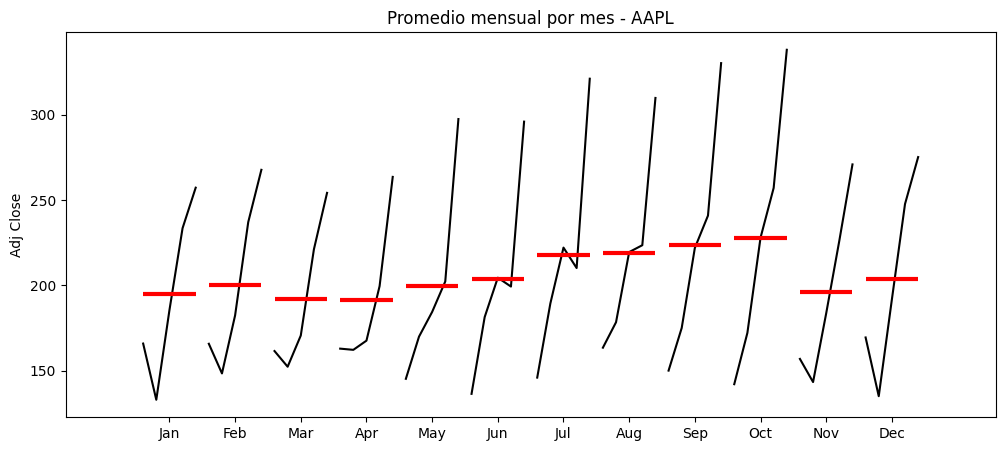

In [25]:
# Gráfica para detección de estacionalidad mensual:
fig = month_plot(train['y'].resample('M').mean(), ylabel='Adj Close')
fig.set_size_inches(12,5)   # (mejora) más ancha para que se lean los 12 meses
plt.title('Promedio mensual por mes - AAPL')
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------

Las líneas negras muestran el precio de cada mes a lo largo de los años y la línea roja su promedio.

* En todos los meses las líneas negras van hacia arriba, es decir, cada año el precio fue mayor que el anterior (efecto de la tendencia).
* Los promedios van de unos 192 dólares (marzo-abril) a unos 228 (octubre), pero la diferencia entre meses es pequeña comparada con el crecimiento de un año a otro.
* Por eso **no se observa una estacionalidad mensual fuerte** en el precio de AAPL.

-----------------------------------------------------------------------------

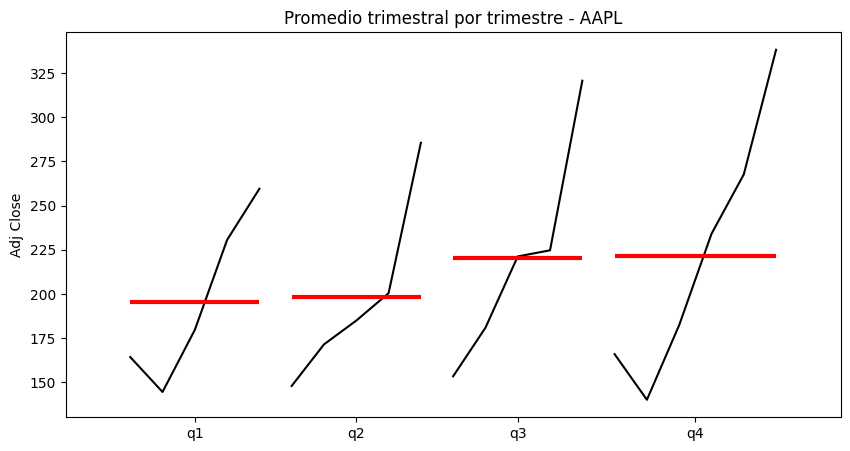

In [26]:
# Si queremos graficar y detectar estacionalidad trimestral:
fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Adj Close')
fig.set_size_inches(10,5)   # (mejora) más ancha
plt.title('Promedio trimestral por trimestre - AAPL')
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------

* Los promedios trimestrales son parecidos: q1 ≈ 196, q2 ≈ 199, q3 ≈ 221 y q4 ≈ 222 dólares. La segunda mitad del año es un poco más alta.
* En los cuatro trimestres las líneas suben año con año, así que la diferencia se debe más a la tendencia que a un patrón por trimestre.
* La **estacionalidad trimestral es débil**.

-----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

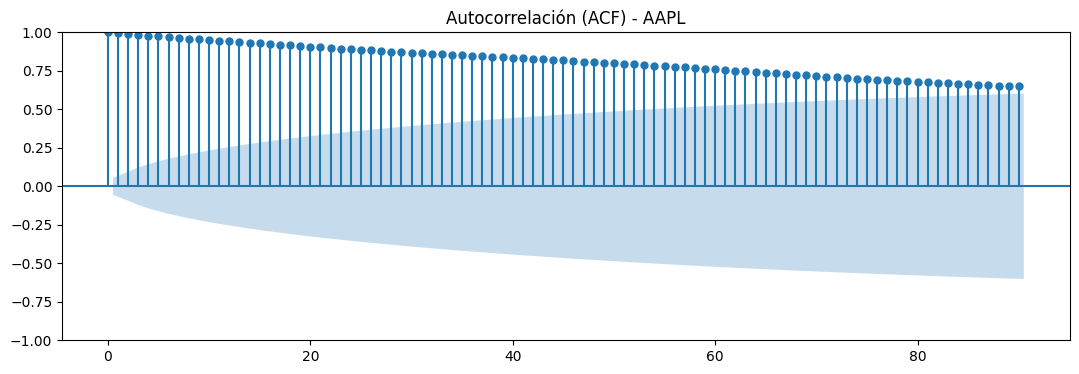

In [27]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
plot_acf(train['y'], lags=90, ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
ax.set_title('Autocorrelación (ACF) - AAPL')
plt.show()

# <font color=orange>**Intepretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------

* Todos los rezagos (hasta 90) están fuera de la zona sombreada y bajan muy lentamente (de 1 a cerca de 0.65).
* Esto indica que el precio de hoy depende mucho de los días anteriores y que la serie **no es estacionaria** (tiene tendencia).
* Por eso, antes de aplicar ARIMA, se diferencia la serie (precio de hoy menos el de ayer), lo que equivale a usar d = 1.

-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**Para AAPL, el ACF no se corta en ningún rezago (baja muy lento), lo cual indica tendencia. Por eso primero se aplica una diferencia y se usa un valor pequeño de q (q = 1).**

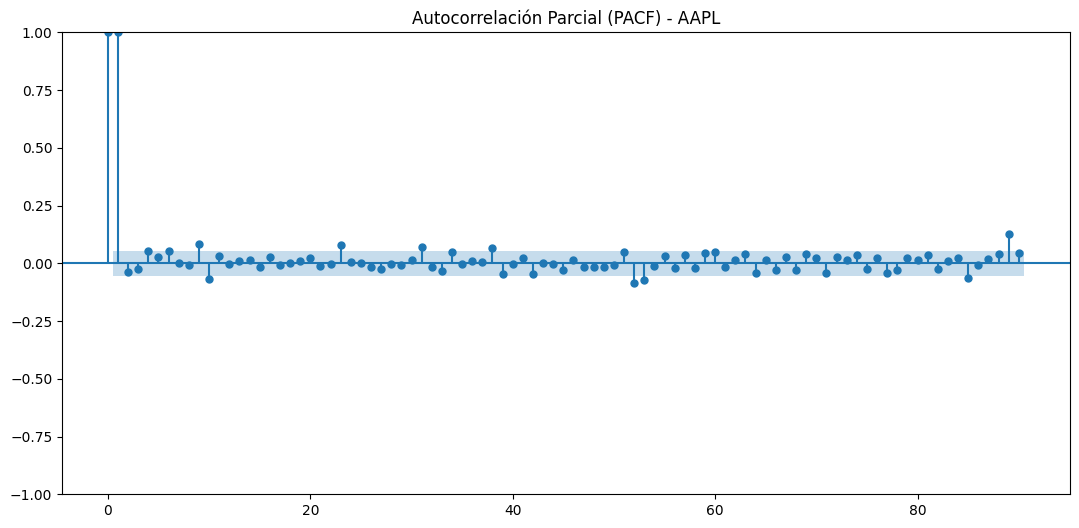

In [28]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
plot_pacf(train['y'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
ax.set_title('Autocorrelación Parcial (PACF) - AAPL')
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autoccorelation (PACF)**

-----------------------------------------------------------------------------

* Solo el rezago 1 sale claramente de la zona sombreada (con valor cercano a 1); los demás quedan dentro o muy cerca del límite.
* Esto significa que el precio de hoy depende directamente casi solo del precio del día anterior.
* Por eso se elige p = 1 para la parte AR del modelo.

-----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p = 1, ya que solo el primer rezago es significativo. Con esto se usa ARIMA(1,0,1) sobre la serie diferenciada.**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [29]:
from statsmodels.tsa.arima.model import ARIMA

In [30]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [31]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  diff = difference(history,1)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,1),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit()  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, 1)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 343, Predicción = 339.239
>Esperado-real = 347, Predicción = 344.028
>Esperado-real = 347, Predicción = 348.292
>Esperado-real = 343, Predicción = 347.615
>Esperado-real = 346, Predicción = 343.636
>Esperado-real = 343, Predicción = 347.087
>Esperado-real = 348, Predicción = 343.596
>Esperado-real = 344, Predicción = 348.967
>Esperado-real = 338, Predicción = 344.377
>Esperado-real = 331, Predicción = 337.940
>Esperado-real = 349, Predicción = 331.479
>Esperado-real = 343, Predicción = 349.948
>Esperado-real = 342, Predicción = 344.187
>Esperado-real = 350, Predicción = 342.191
>Esperado-real = 348, Predicción = 350.781
>Esperado-real = 355, Predicción = 348.358
>Esperado-real = 354, Predicción = 355.678
>Esperado-real = 356, Predicción = 355.041
>Esperado-real = 352, Predicción = 356.430
>Esperado-real = 352, Predicción = 352.941

Error-Modelo-ARIMA: RMSE: 5.898


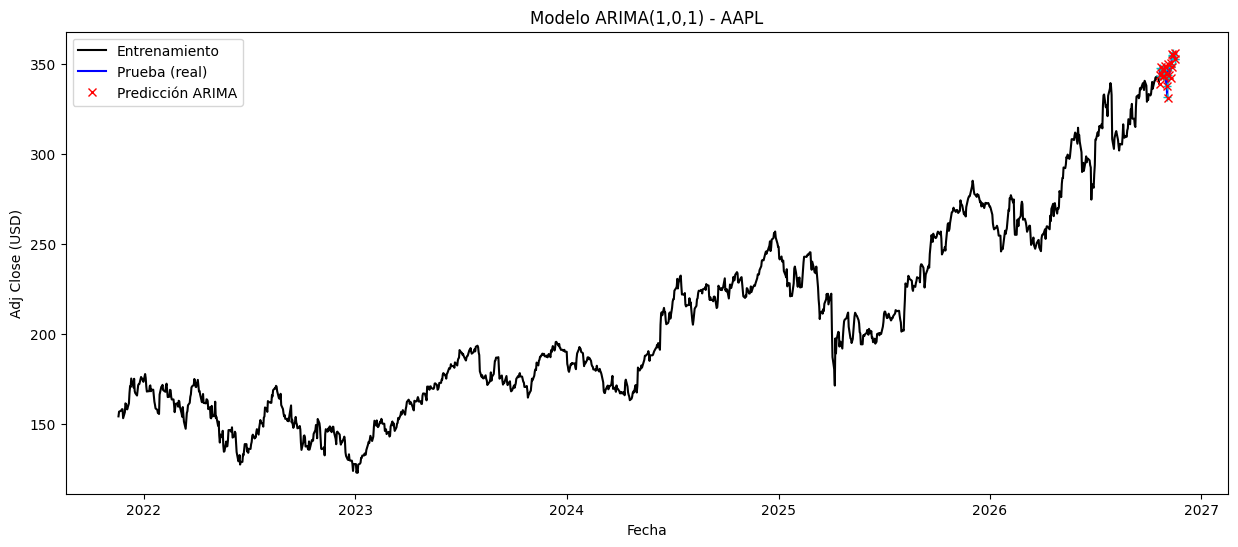

In [32]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k', label='Entrenamiento')
ax = plt.plot(test['y'], '-b', label='Prueba (real)')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr', label='Predicción ARIMA')
plt.title('Modelo ARIMA(1,0,1) - AAPL')   # (mejora) título, ejes y leyenda
plt.xlabel('Fecha')
plt.ylabel('Adj Close (USD)')
plt.legend()
plt.show()

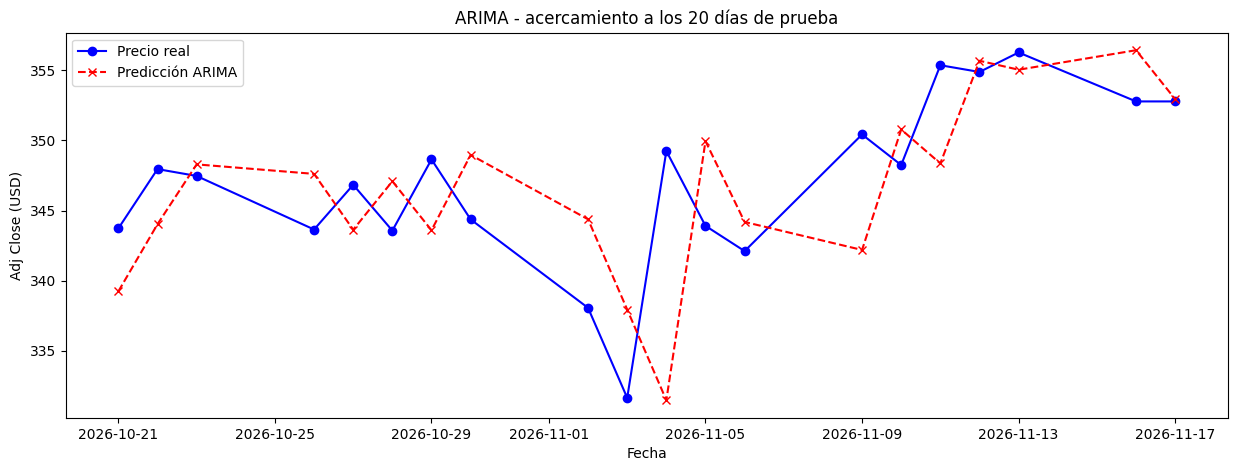

In [33]:
# (mejora) Acercamiento: solo los 20 días de prueba para ver bien la diferencia
# entre el precio real y la predicción (en la gráfica completa se ven encimados).
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test.index, test['y'], '-ob', label='Precio real')
ax.plot(test.index, predictions, '--xr', label='Predicción ARIMA')
ax.set_title('ARIMA - acercamiento a los 20 días de prueba')
ax.set_xlabel('Fecha')
ax.set_ylabel('Adj Close (USD)')
ax.legend()
plt.show()

# <font color=orange>**Interpretación Gráfica ARIMA**

-----------------------------------------------------------------------------

* El ARIMA(1,0,1) obtuvo un **RMSE de 5.898**, prácticamente igual al del modelo ingenuo (5.826).
* En el acercamiento se ve que la predicción (línea roja) sigue al precio real, pero con un día de retraso: predice casi el mismo valor del día anterior.
* Esto pasa porque los cambios diarios del precio son casi aleatorios, así que el modelo no encuentra un patrón que le permita mejorar al ingenuo.
* No anticipa los cambios bruscos, por ejemplo la caída del 3 de noviembre (331.65 dólares) y la subida del día siguiente.

-----------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [34]:
df_temp.head() #verificar que el df_temp este en formato correcto

,y
Date,
2021-11-18,154.089462
2021-11-19,156.705307
2021-11-22,157.164047
2021-11-23,157.544724
2021-11-24,158.062027


In [35]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,y
0,2021-11-18,154.089462
1,2021-11-19,156.705307
2,2021-11-22,157.164047
3,2021-11-23,157.544724
4,2021-11-24,158.062027


In [36]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [37]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [38]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 7.823


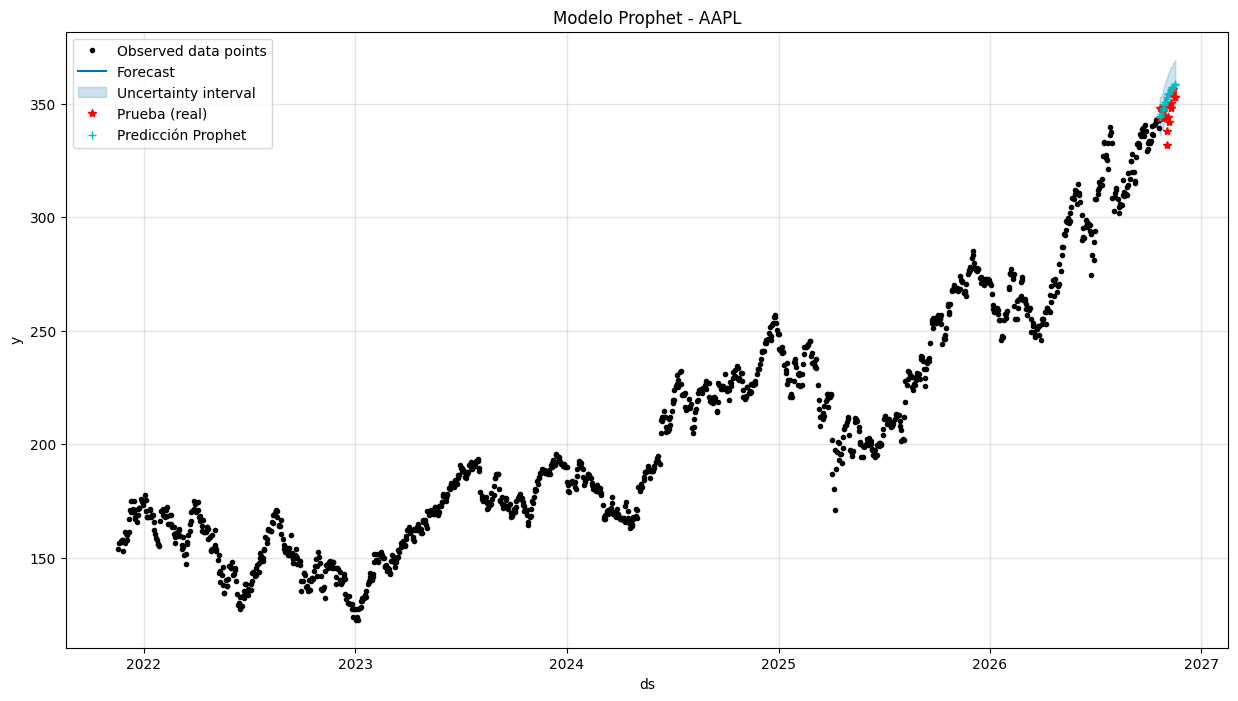

In [39]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r', label='Prueba (real)')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c', label='Predicción Prophet')    # Predicciones.

#color rojo representan los datos reales de prueba
#color cian las predicciones
plt.title('Modelo Prophet - AAPL')   # (mejora) título y leyenda
plt.legend()
plt.show()

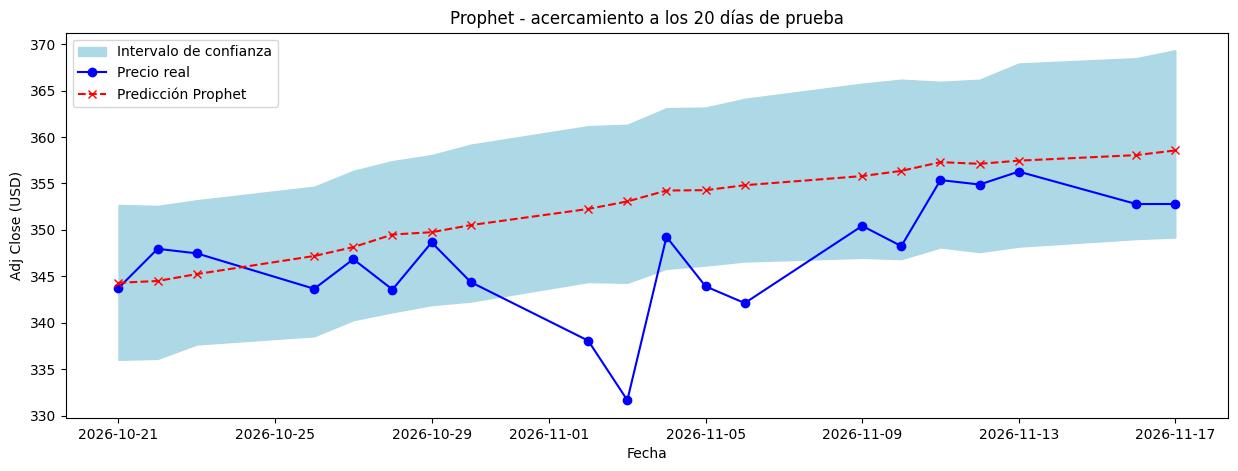

In [40]:
# (mejora) Acercamiento a los 20 días de prueba con su intervalo de confianza:
fig, ax = plt.subplots(figsize=(15, 5))
ax.fill_between(test['ds'], forecast['yhat_lower'], forecast['yhat_upper'], color='lightblue', label='Intervalo de confianza')
ax.plot(test['ds'], test['y'], '-ob', label='Precio real')
ax.plot(test['ds'], forecast['yhat'], '--xr', label='Predicción Prophet')
ax.set_title('Prophet - acercamiento a los 20 días de prueba')
ax.set_xlabel('Fecha')
ax.set_ylabel('Adj Close (USD)')
ax.legend()
plt.show()

# <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet**

-----------------------------------------------------------------------------

Puntos rojos -> datos reales de prueba
Cruces cian / línea roja punteada -> predicciones
Parte sombreada -> intervalo de confianza de la predicción

* Prophet obtuvo un **RMSE de 7.823**, mayor que el del ingenuo y ARIMA.
* Su predicción es una línea suave que sube de unos 344 a 358 dólares, porque sigue la tendencia general y no los cambios de cada día.
* En la mayoría de los días sobreestima el precio (la línea roja queda arriba de la azul).
* Casi todos los valores reales quedan dentro del intervalo de confianza, excepto la caída del 3 de noviembre.

-----------------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [41]:
import tensorflow as tf

In [42]:
test.head()

,ds,y
1284,2026-10-21,343.728821
1285,2026-10-22,347.955627
1286,2026-10-23,347.466003
1287,2026-10-26,343.648895
1288,2026-10-27,346.836487


In [43]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 meses al año

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [44]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date = df_temp['ds'].iloc[-48]   # A partir de esta fecha se empieza a generar el Test.
# (adaptado a AAPL) Tomamos la fecha que está 48 registros antes del final: 48 = 4 bloques de 12,
# así los últimos 20 valores que predice el LSTM coinciden con los 20 días de Test.
print(threshold_Date)

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp, threshold_Date)#aplica df temporal

2026-09-11 00:00:00


In [45]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 100:
    lrate = 0.05
  elif epoch <= 180:
    lrate = 0.0005
  elif epoch <=190:
    lrate = 0.00005
  else:
    lrate = (10 ** -5)

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - loss: 42404.2344 - root_mean_squared_error: 205.9229 - val_loss: 49751.7383 - val_root_mean_squared_error: 223.0510 - learning_rate: 0.0500
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 28568.7715 - root_mean_squared_error: 169.0230 - val_loss: 299951.2500 - val_root_mean_squared_error: 547.6781 - learning_rate: 0.0500
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 4049.6978 - root_mean_squared_error: 63.6372 - val_loss: 1043771.2500 - val_root_mean_squared_error: 1021.6512 - learning_rate: 0.0500
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 7372.0220 - root_mean_squared_error: 85.8605 - val_loss: 83860.7500 - val_root_mean_squared_error: 289.5872 - learning_rate: 0.0500
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 3209.9399 - root_mean_squared_error: 56.6563 - val_loss: 22024.4062 - val_root_mean_squared_error: 148.4062 - learning_rate: 0.0500
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 3

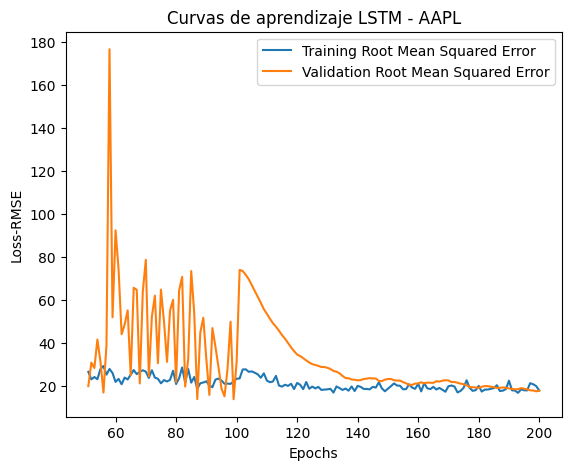

In [46]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model


# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.set_title('Curvas de aprendizaje LSTM - AAPL')
ax2.legend()

plt.show()

In [47]:
pred_LSTM=my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step


(432,)

In [48]:
# Calculamos el error RMSE:

pred_LSTM = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM = pred_LSTM.reshape(-1)[-20:]  # Elegir los últimos 20 valores
rmse = np.sqrt(mean_squared_error(test['y'].values, pred_LSTM))

print('\nError-Modelo-LSTM: RMSE: %.3f' % rmse)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step

Error-Modelo-LSTM: RMSE: 14.453


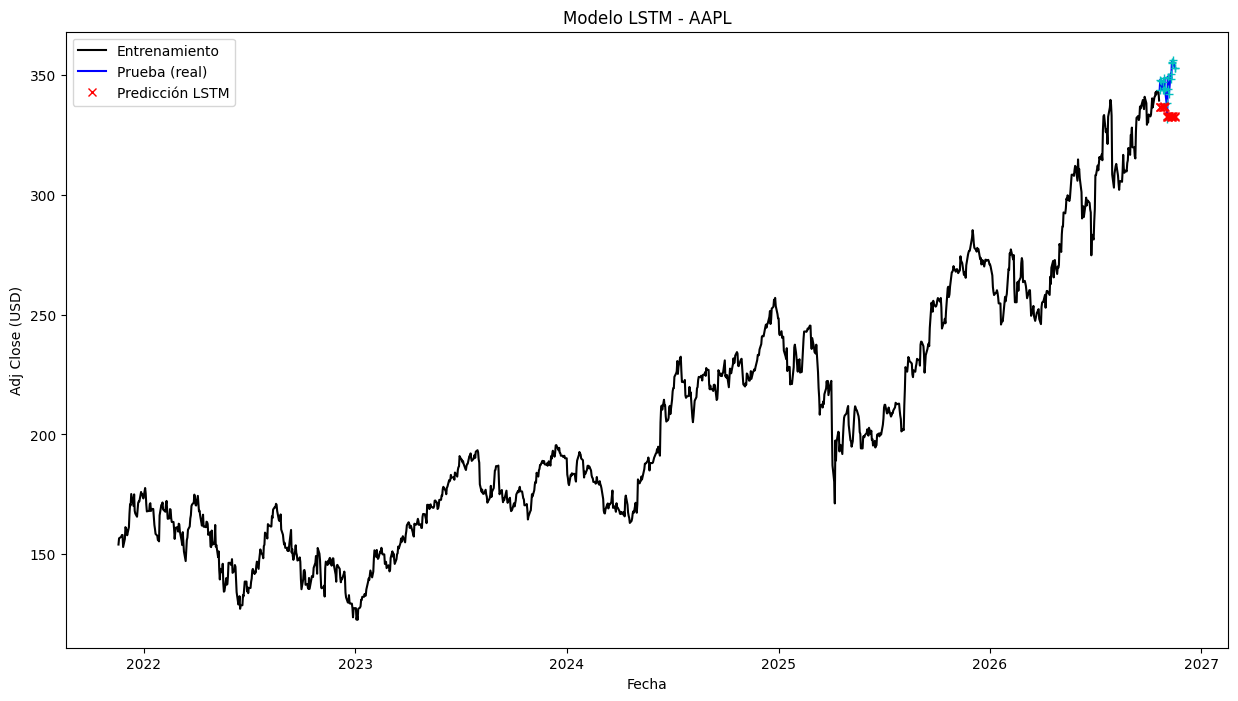

In [49]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 8))
ax = plt.plot(train['ds'], train['y'], '-k', label='Entrenamiento')  # Datos de entrenamiento.
ax = plt.plot(test['ds'], test['y'], '-b', label='Prueba (real)')    # Datos de prueba (últimos 20 días).
ax = plt.plot(test['ds'], test['y'], '+c')    # Datos de prueba (últimos 20 días).
ax = plt.plot(test['ds'], pred_LSTM, 'xr', label='Predicción LSTM')  # Predicciones del modelo.
plt.title('Modelo LSTM - AAPL')   # (mejora) título, ejes y leyenda
plt.xlabel('Fecha')
plt.ylabel('Adj Close (USD)')
plt.legend()
plt.show()

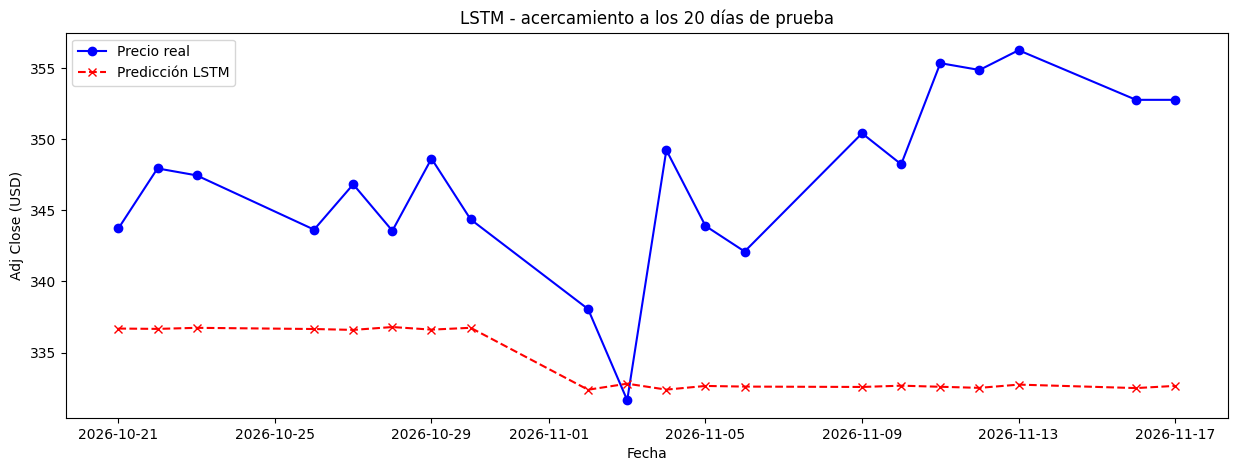

In [50]:
# (mejora) Acercamiento a los 20 días de prueba:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test['ds'], test['y'], '-ob', label='Precio real')
ax.plot(test['ds'], pred_LSTM, '--xr', label='Predicción LSTM')
ax.set_title('LSTM - acercamiento a los 20 días de prueba')
ax.set_xlabel('Fecha')
ax.set_ylabel('Adj Close (USD)')
ax.legend()
plt.show()

**Habría que buscar la mejor arquitectura y ejecutarlo varias veces para obtener un mejor resultado.**

# <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**

-----------------------------------------------------------------------------

* El LSTM obtuvo un **RMSE de 14.453**, el más alto de los cuatro modelos.
* Sus predicciones son casi planas (entre 332 y 337 dólares) y quedan por debajo del precio real (343-356), es decir, subestima y no capta la subida del final.
* En la curva de aprendizaje, el error de validación es muy inestable hasta la época 100; después baja y termina cerca de 18, al nivel del entrenamiento.
* El modelo aprende el nivel general del precio, pero no sus movimientos, porque tiene pocos ejemplos (bloques de 12 días) para entrenar.

*Nota: la fecha de corte del LSTM se tomó 48 registros antes del final (4 bloques de 12) para que los últimos 20 valores predichos coincidan con los 20 días de prueba.*

-----------------------------------------------------------------------------

# <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos Ingenuo, ARIMA, Prophet y LSTM aplicado con Datos Orginales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE, fueron los siguientes:

| # | Modelo  | Datos Originales RMSE |
|---|---------|-----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 5.826 |
| 2 | Modelo ARIMA | 5.898 |
| 3 | Modelo Facebook-Meta-Prophet | 7.823 |
| 4 | Long Short Term Memory (LSTM) | 14.453 |

**<font color=orange>INTERPRETACIÓN Y CONCLUSIÓN DE LA PRÁCTICA: </FONT>**

* El modelo ingenuo y ARIMA tuvieron el menor error, de casi 6 dólares, que es menos del 2% de un precio de alrededor de 345 dólares.
* ARIMA no logró mejorar al modelo ingenuo, lo que indica que el mejor estimado del precio de mañana es prácticamente el precio de hoy.
* Prophet capta bien la tendencia, pero no los cambios diarios, por lo que su error es un poco mayor.
* El LSTM fue el peor; necesitaría más datos y probar otras arquitecturas para mejorar.

-----------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (ADJ-CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [51]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

In [52]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,y,y_escalado
0,2021-11-18,154.089462,0.142223
1,2021-11-19,156.705307,0.154088
2,2021-11-22,157.164047,0.156169
3,2021-11-23,157.544724,0.157895
4,2021-11-24,158.062027,0.160242


In [53]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [54]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,y_escalado
0,2021-11-18,0.142223
1,2021-11-19,0.154088
2,2021-11-22,0.156169
3,2021-11-23,0.157895
4,2021-11-24,0.160242


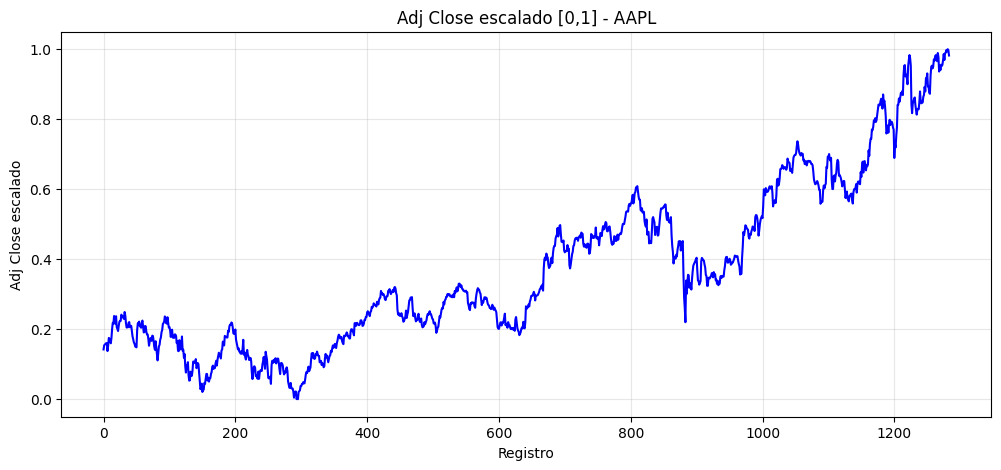

In [55]:
train_escalado['y_escalado'].plot(title='Adj Close escalado [0,1] - AAPL', style='-b', figsize=(12, 5))   # (mejora) tamaño
plt.xlabel('Registro')
plt.ylabel('Adj Close escalado')
plt.grid(alpha=0.3)
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo Obtenido en Datos Originales**

-----------------------------------------------------------------------------

* La forma de la gráfica es **idéntica** a la de los datos originales; solo cambió la escala del eje vertical a valores entre 0 y 1.
* El 0 corresponde al precio más bajo del entrenamiento (≈123 dólares, inicio de 2023) y el 1 al más alto (≈343 dólares).
* El escalamiento no cambia la tendencia ni las subidas y bajadas, solo las unidades.
* Los datos de prueba quedan un poco arriba de 1 (entre 0.95 y 1.06), porque en esos días el precio superó el máximo del entrenamiento.

-----------------------------------------------------------------------------

In [56]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([1.00240221, 1.02157445, 1.01935358, 1.00203967, 1.01649818,
       1.001677  , 1.02470186, 1.00530302, 0.97670342, 0.94760521,
       1.02742134, 1.00321808, 0.99505966, 1.03276948, 1.02288879,
       1.05515966, 1.05298253, 1.05928732, 1.04345718, 1.04345718])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [57]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 1.002, Predicción = 0.982
>Esperado-real = 1.022, Predicción = 1.002
>Esperado-real = 1.019, Predicción = 1.022
>Esperado-real = 1.002, Predicción = 1.019
>Esperado-real = 1.016, Predicción = 1.002
>Esperado-real = 1.002, Predicción = 1.016
>Esperado-real = 1.025, Predicción = 1.002
>Esperado-real = 1.005, Predicción = 1.025
>Esperado-real = 0.977, Predicción = 1.005
>Esperado-real = 0.948, Predicción = 0.977
>Esperado-real = 1.027, Predicción = 0.948
>Esperado-real = 1.003, Predicción = 1.027
>Esperado-real = 0.995, Predicción = 1.003
>Esperado-real = 1.033, Predicción = 0.995
>Esperado-real = 1.023, Predicción = 1.033
>Esperado-real = 1.055, Predicción = 1.023
>Esperado-real = 1.053, Predicción = 1.055
>Esperado-real = 1.059, Predicción = 1.053
>Esperado-real = 1.043, Predicción = 1.059
>Esperado-real = 1.043, Predicción = 1.043

Error-Modelo-Naive con datos escalados: RMSE: 0.026


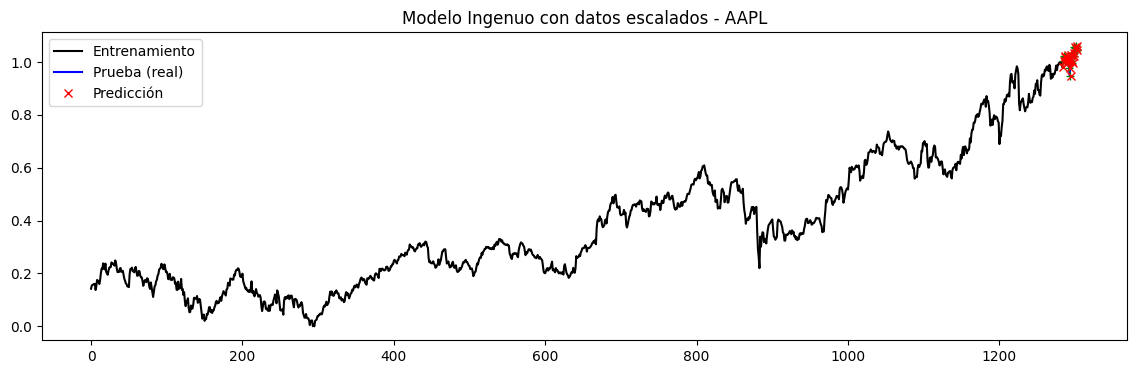

In [58]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k', label='Entrenamiento')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b', label='Prueba (real)')    # Datos de prueba reales (los últimos 20 días a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr', label='Predicción')
plt.title('Modelo Ingenuo con datos escalados - AAPL')   # (mejora)
plt.legend()
plt.show()

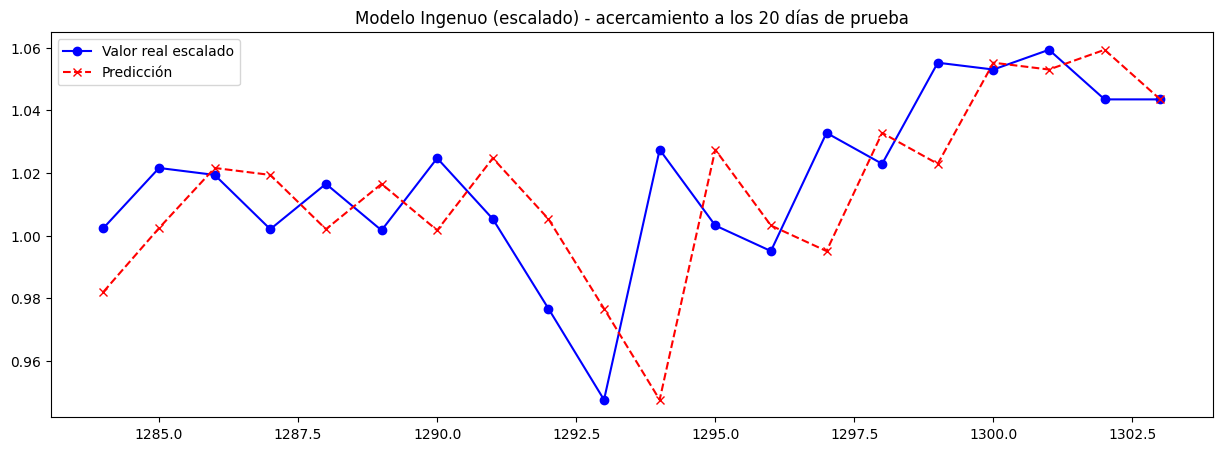

In [59]:
# (mejora) Acercamiento a los 20 días de prueba (datos escalados):
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test_escalado.index, test_escalado['y_escalado'], '-ob', label='Valor real escalado')
ax.plot(test_escalado.index, predictions, '--xr', label='Predicción')
ax.set_title('Modelo Ingenuo (escalado) - acercamiento a los 20 días de prueba')
ax.legend()
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en el modelo ingenuo con los datos originales**

-----------------------------------------------------------------------------

* El comportamiento es el mismo que con datos originales: cada predicción es el valor real del día anterior.
* El **RMSE fue de 0.026**. Si se regresa a dólares (multiplicando por el rango de ≈220.5 dólares) da ≈5.8 dólares, prácticamente el mismo error que con datos originales (5.826).
* El RMSE se ve más pequeño solo porque está en otra escala, no porque el modelo sea mejor.

-----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [60]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,y_escalado
0,2021-11-18,0.142223
1,2021-11-19,0.154088
2,2021-11-22,0.156169
3,2021-11-23,0.157895
4,2021-11-24,0.160242


In [61]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,y_escalado
1284,2026-10-21,1.002402
1285,2026-10-22,1.021574
1286,2026-10-23,1.019354
1287,2026-10-26,1.002040
1288,2026-10-27,1.016498


In [62]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [63]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [64]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,y_escalado
ds,
2021-11-18,0.142223
2021-11-19,0.154088
2021-11-22,0.156169
2021-11-23,0.157895
2021-11-24,0.160242


In [65]:
test_escalado2.head() #Verificar datos Escalados Prueba

,y_escalado
ds,
2026-10-21,1.002402
2026-10-22,1.021574
2026-10-23,1.019354
2026-10-26,1.002040
2026-10-27,1.016498


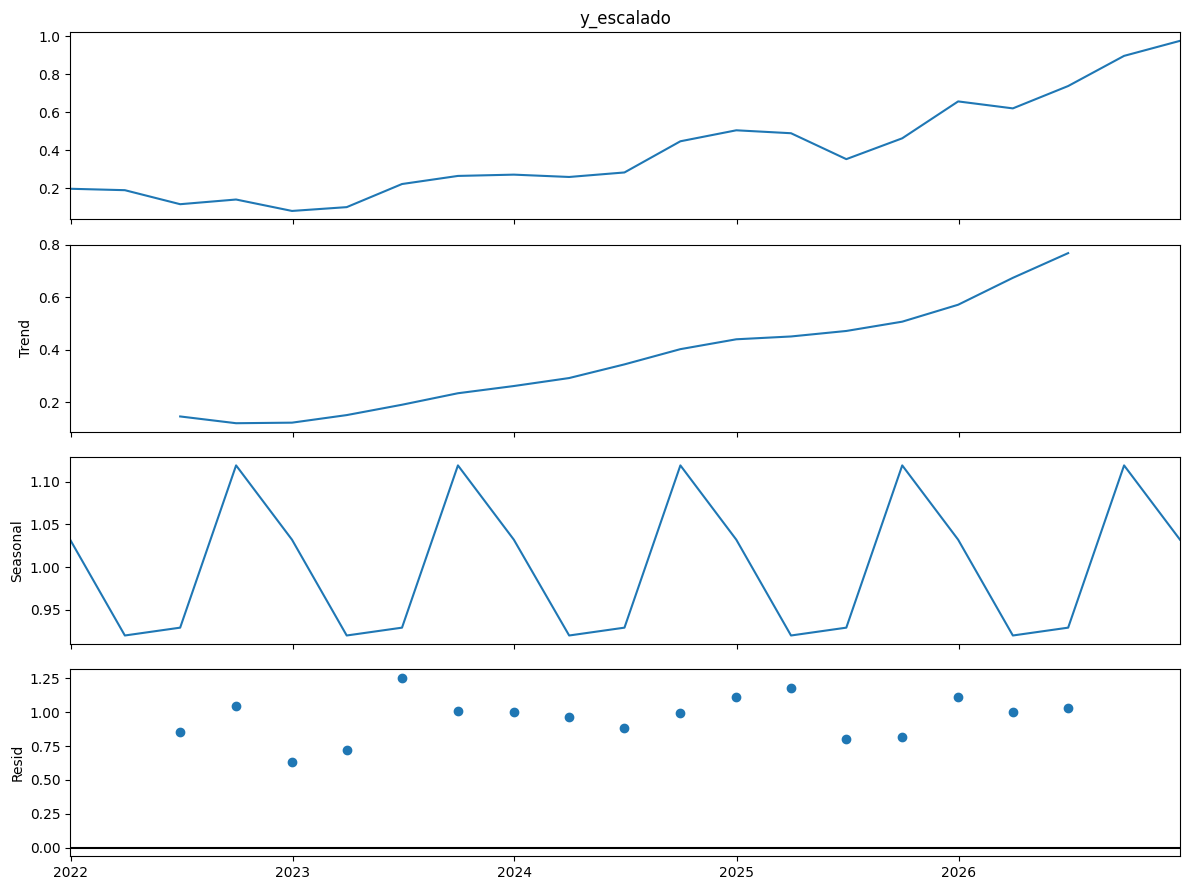

In [66]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(12,9)   # (mejora)
plt.tight_layout()
plt.show()

# <FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con Datos Originales**

-----------------------------------------------------------------------------

* La tendencia es la misma que en los datos originales: creciente, sobre todo en 2025-2026.
* La componente estacional mantiene el mismo patrón anual, pero ahora varía más (de 0.92 a 1.12) y los residuos también se dispersan más (de 0.63 a 1.25).
* Esto pasa porque el modelo es multiplicativo (trabaja con proporciones) y los valores escalados de 2022-2023 están muy cerca de 0, lo que exagera las proporciones.
* Las gráficas mensual, trimestral, ACF y PACF escaladas son iguales a las originales, solo cambia la escala del eje vertical, por lo que se mantienen p = 1 y q = 1.

-----------------------------------------------------------------------------

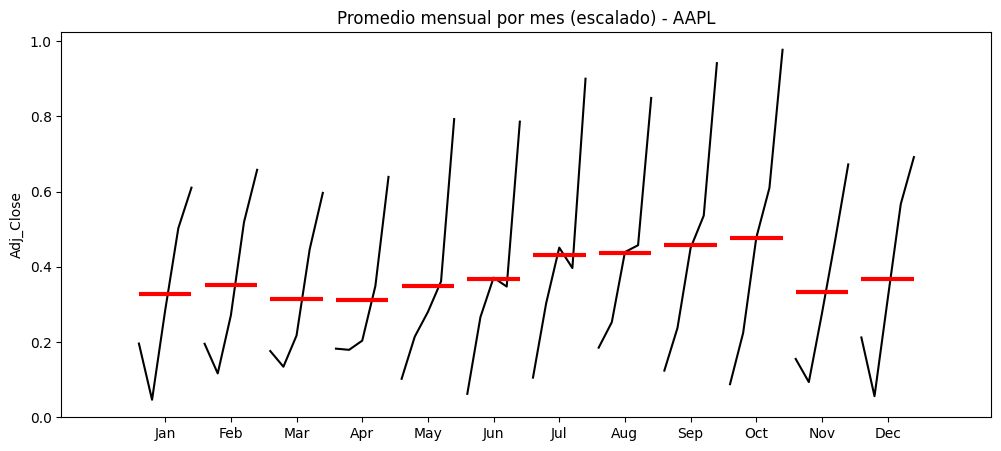

In [67]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(12,5)   # (mejora)
plt.title('Promedio mensual por mes (escalado) - AAPL')
plt.show()

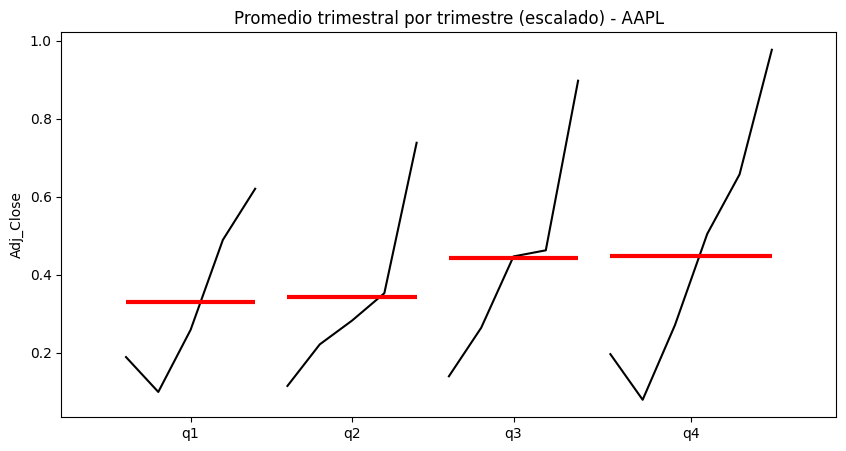

In [68]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(10,5)   # (mejora)
plt.title('Promedio trimestral por trimestre (escalado) - AAPL')
plt.show()

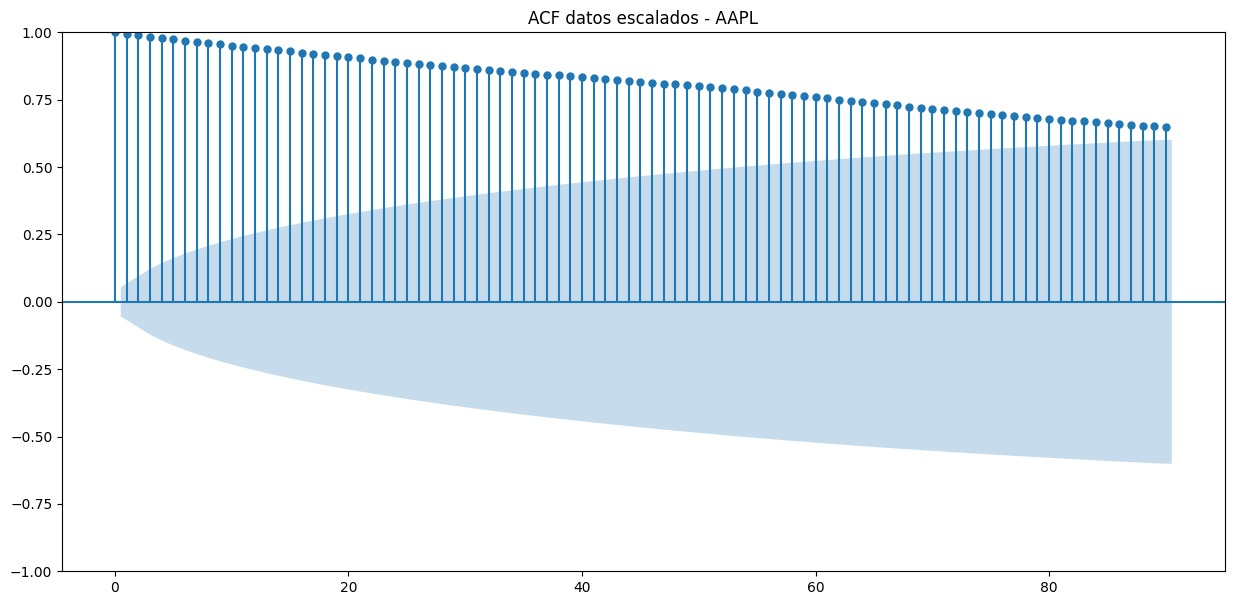

In [69]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
plot_acf(train_escalado2['y_escalado'], lags = 90,ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
ax.set_title('ACF datos escalados - AAPL')
plt.show()                          # que define la partición en el eje horizontal. El área no sombreada nos habla de
                                    # la cantidad de períodos de tiempo hacia atrás cuya información proporcionada es
                                    # significativa para la predicción futura.


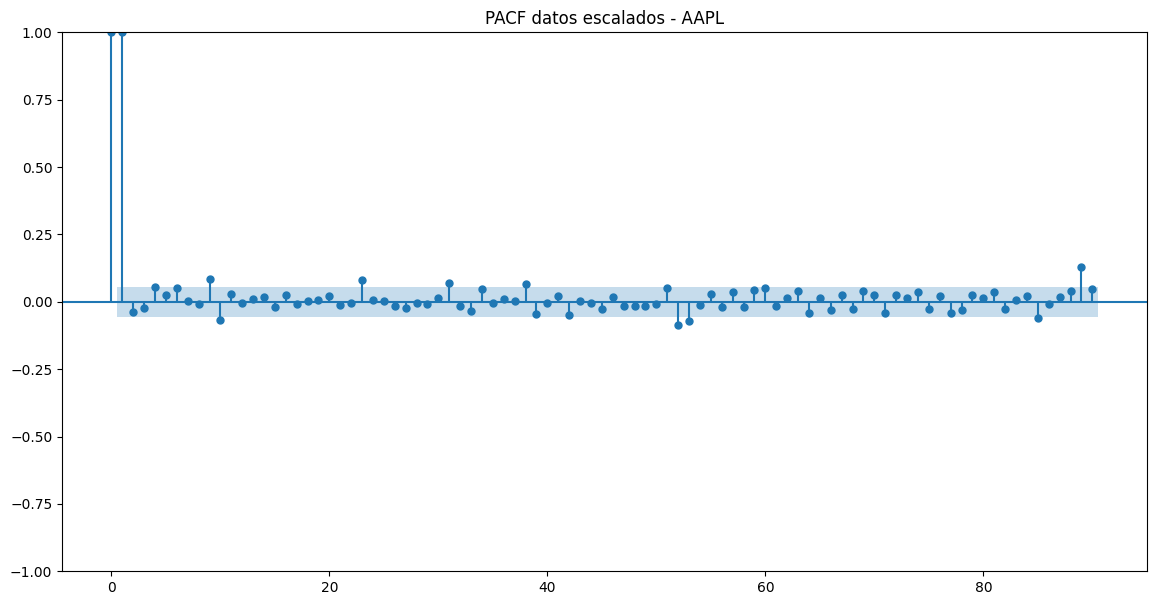

In [70]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
ax.set_title('PACF datos escalados - AAPL')
plt.show()

In [71]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 1   # (adaptado) diferencia de 1 día, igual que en el ARIMA con datos originales
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,1),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 1.002, Predicción = 0.982
>Esperado-real = 1.022, Predicción = 1.004
>Esperado-real = 1.019, Predicción = 1.023
>Esperado-real = 1.002, Predicción = 1.020
>Esperado-real = 1.016, Predicción = 1.002
>Esperado-real = 1.002, Predicción = 1.018
>Esperado-real = 1.025, Predicción = 1.002
>Esperado-real = 1.005, Predicción = 1.026
>Esperado-real = 0.977, Predicción = 1.005
>Esperado-real = 0.948, Predicción = 0.976
>Esperado-real = 1.027, Predicción = 0.947
>Esperado-real = 1.003, Predicción = 1.030
>Esperado-real = 0.995, Predicción = 1.004
>Esperado-real = 1.033, Predicción = 0.996
>Esperado-real = 1.023, Predicción = 1.034
>Esperado-real = 1.055, Predicción = 1.023
>Esperado-real = 1.053, Predicción = 1.056
>Esperado-real = 1.059, Predicción = 1.054
>Esperado-real = 1.043, Predicción = 1.060
>Esperado-real = 1.043, Predicción = 1.044

Error-Modelo-ARIMA: RMSE: 0.027


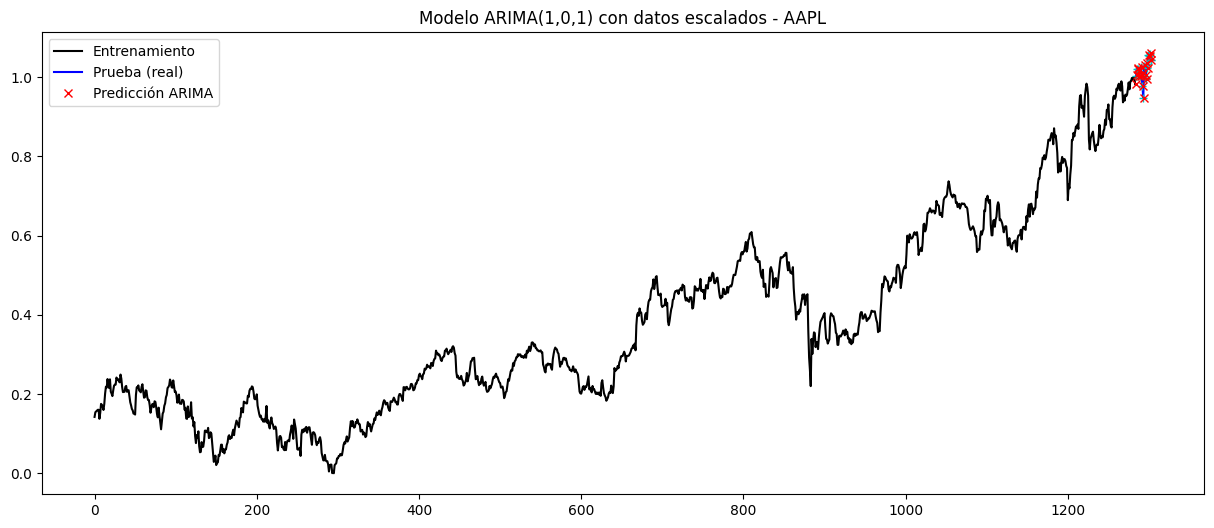

In [72]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k', label='Entrenamiento')
ax = plt.plot(test_escalado['y_escalado'], '-b', label='Prueba (real)')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr', label='Predicción ARIMA')
plt.title('Modelo ARIMA(1,0,1) con datos escalados - AAPL')   # (mejora)
plt.legend()
plt.show()

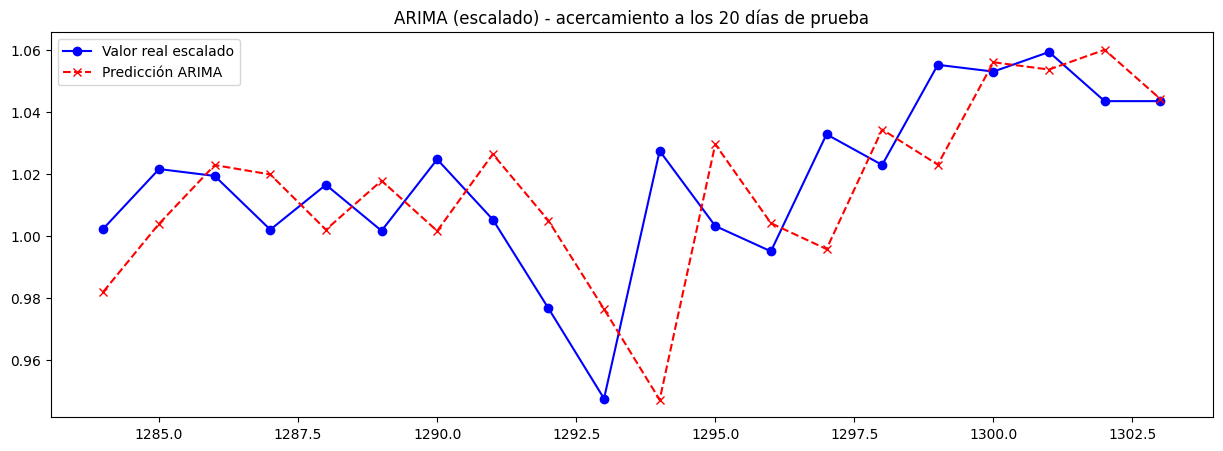

In [73]:
# (mejora) Acercamiento a los 20 días de prueba (datos escalados):
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test_escalado.index, test_escalado['y_escalado'], '-ob', label='Valor real escalado')
ax.plot(test_escalado.index, predictions_escalado, '--xr', label='Predicción ARIMA')
ax.set_title('ARIMA (escalado) - acercamiento a los 20 días de prueba')
ax.legend()
plt.show()

# <FONT COLOR=ORANGE>**Interpretación Gráfica Modelo ARIMA, Comparativa con datos originales**

-----------------------------------------------------------------------------

* El ARIMA con datos escalados obtuvo un **RMSE de 0.027**, que en dólares equivale a ≈5.9, casi igual al de datos originales (5.898).
* En el acercamiento la predicción vuelve a seguir al valor real con un día de retraso, igual que con datos originales.
* El escalamiento no cambió el resultado de ARIMA, porque es un modelo lineal: escalar solo cambia las unidades.

*Nota: se usó la misma diferencia de 1 día y el mismo ARIMA(1,0,1) que con datos originales, para comparar en igualdad de condiciones.*

-----------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [74]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,y
0,2021-11-18,154.089462
1,2021-11-19,156.705307
2,2021-11-22,157.164047
3,2021-11-23,157.544724
4,2021-11-24,158.062027


In [75]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,y
0,2021-11-18,154.089462
1,2021-11-19,156.705307
2,2021-11-22,157.164047
3,2021-11-23,157.544724
4,2021-11-24,158.062027


In [76]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [77]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [78]:
train_escalado.head()

,ds,y
0,2021-11-18,0.142223
1,2021-11-19,0.154088
2,2021-11-22,0.156169
3,2021-11-23,0.157895
4,2021-11-24,0.160242


In [79]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [80]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.031


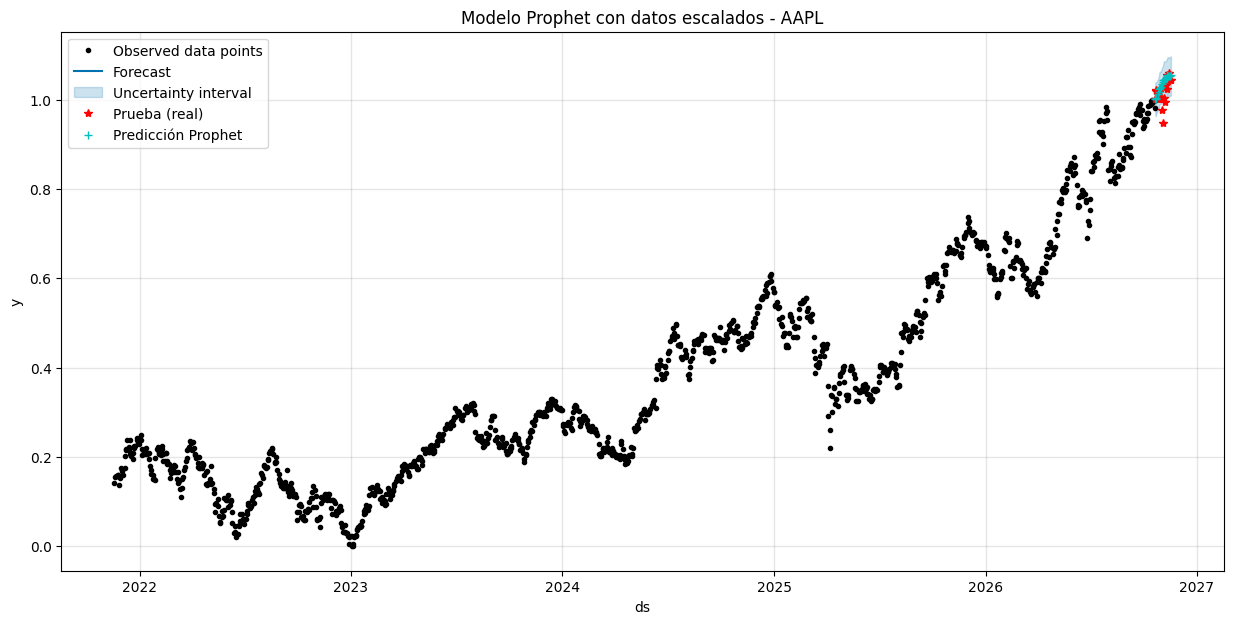

In [81]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(15, 7))   # (mejora) tamaño más manejable
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r', label='Prueba (real)') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c', label='Predicción Prophet')  # Predicciones.
plt.title('Modelo Prophet con datos escalados - AAPL')
plt.legend()
plt.show()

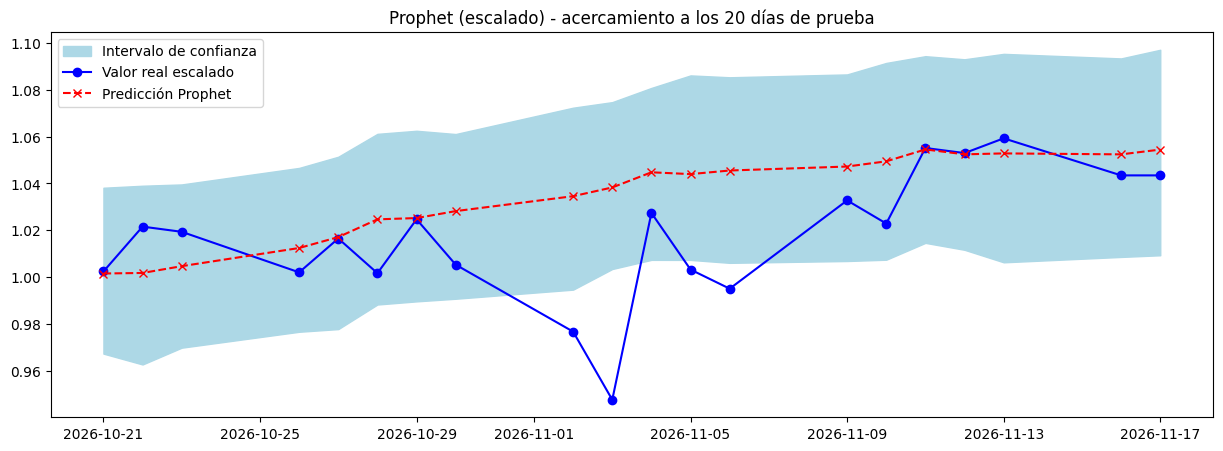

In [82]:
# (mejora) Acercamiento a los 20 días de prueba (datos escalados):
fig, ax = plt.subplots(figsize=(15, 5))
ax.fill_between(test_escalado['ds'], forecast_escalado['yhat_lower'], forecast_escalado['yhat_upper'], color='lightblue', label='Intervalo de confianza')
ax.plot(test_escalado['ds'], test_escalado['y'], '-ob', label='Valor real escalado')
ax.plot(test_escalado['ds'], forecast_escalado['yhat'], '--xr', label='Predicción Prophet')
ax.set_title('Prophet (escalado) - acercamiento a los 20 días de prueba')
ax.legend()
plt.show()

##<FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con lo obtenido en datos originales**

-----------------------------------------------------------------------------

* Prophet con datos escalados obtuvo un **RMSE de 0.031**, que en dólares equivale a ≈6.8; es un poco mejor que con datos originales (7.823).
* La predicción vuelve a ser una línea suave que sigue la tendencia, pero ahora queda más cerca de los valores reales, sobre todo en los últimos días.
* Los valores reales caen dentro del intervalo de confianza, excepto la caída del 3 de noviembre.
* La mejora se debe a que los parámetros de flexibilidad (changepoint_prior_scale y seasonality_prior_scale) se comportan diferente cuando los datos están entre 0 y 1.

-----------------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [83]:
test_escalado.head()

,ds,y
1284,2026-10-21,1.002402
1285,2026-10-22,1.021574
1286,2026-10-23,1.019354
1287,2026-10-26,1.002040
1288,2026-10-27,1.016498


In [84]:
df_temp_escalado.head()

,ds,y
0,2021-11-18,0.142223
1,2021-11-19,0.154088
2,2021-11-22,0.156169
3,2021-11-23,0.157895
4,2021-11-24,0.160242


In [85]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date_escalado = df_temp_escalado['ds'].iloc[-48]   # A partir de esta fecha se empieza a generar el Test.
# (adaptado a AAPL) 48 registros antes del final = 4 bloques de 12, para que coincida con los 20 días de Test.
print(threshold_Date_escalado)

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)

2026-09-11 00:00:00


In [86]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(200, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model

In [87]:
def scheduler(epoch):
    if epoch <= 50:
        return 0.05
    elif epoch <= 100:
        return 0.01
    elif epoch <= 150:
        return 0.001
    else:
        return 0.0001

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 157ms/step - loss: 5.5258 - root_mean_squared_error: 2.3507 - val_loss: 0.7304 - val_root_mean_squared_error: 0.8546 - learning_rate: 0.0500
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 2.9865 - root_mean_squared_error: 1.7281 - val_loss: 0.8072 - val_root_mean_squared_error: 0.8985 - learning_rate: 0.0500
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 2.0267 - root_mean_squared_error: 1.4236 - val_loss: 0.8610 - val_root_mean_squared_error: 0.9279 - learning_rate: 0.0500
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 1.2786 - root_mean_squared_error: 1.1308 - val_loss: 0.5436 - val_root_mean_squared_error: 0.7373 - learning_rate: 0.0500
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.6859 - root_mean_squared_error: 0.8282 - val_loss: 0.5374 - val_root_mean_squared_error: 0.7331 - learning_rate: 0.0500
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 0.3587 - root_mean_squared_error: 0.5990 

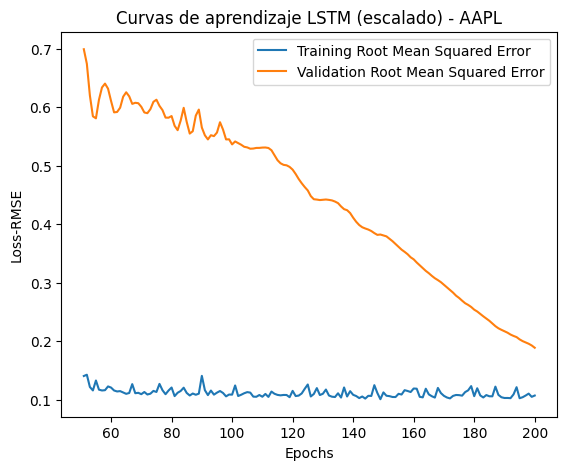

In [88]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.set_title('Curvas de aprendizaje LSTM (escalado) - AAPL')
ax2.legend()

plt.show()

In [89]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step


(432,)

In [90]:
# Calculamos el error RMSE con datos escalados:

pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

print('\nError-Modelo-LSTM con datos escalados: RMSE: %.3f' % rmse)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step

Error-Modelo-LSTM con datos escalados: RMSE: 0.172


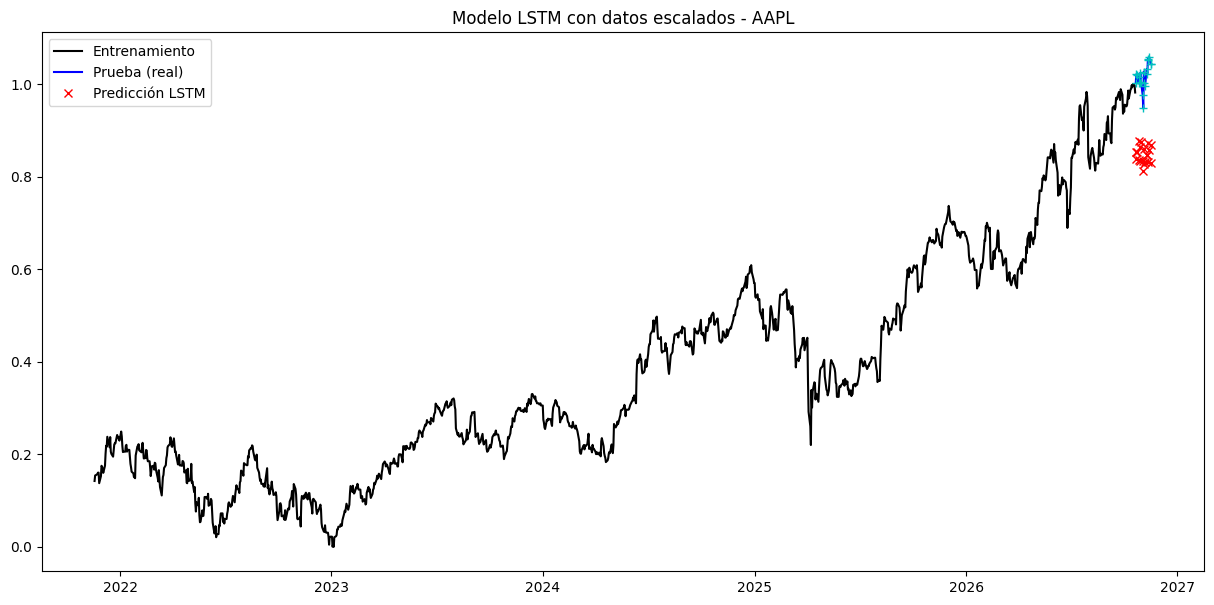

In [91]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 7))   # (mejora) tamaño más manejable
ax = plt.plot(train_escalado['ds'], train_escalado['y'], '-k', label='Entrenamiento')  # Datos de entrenamiento.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '-b', label='Prueba (real)')    # Datos de prueba (últimos 20 días).
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '+c')    # Datos de prueba (últimos 20 días).
ax = plt.plot(test_escalado['ds'], pred_LSTM_escalado, 'xr', label='Predicción LSTM')
plt.title('Modelo LSTM con datos escalados - AAPL')
plt.legend()
plt.show()

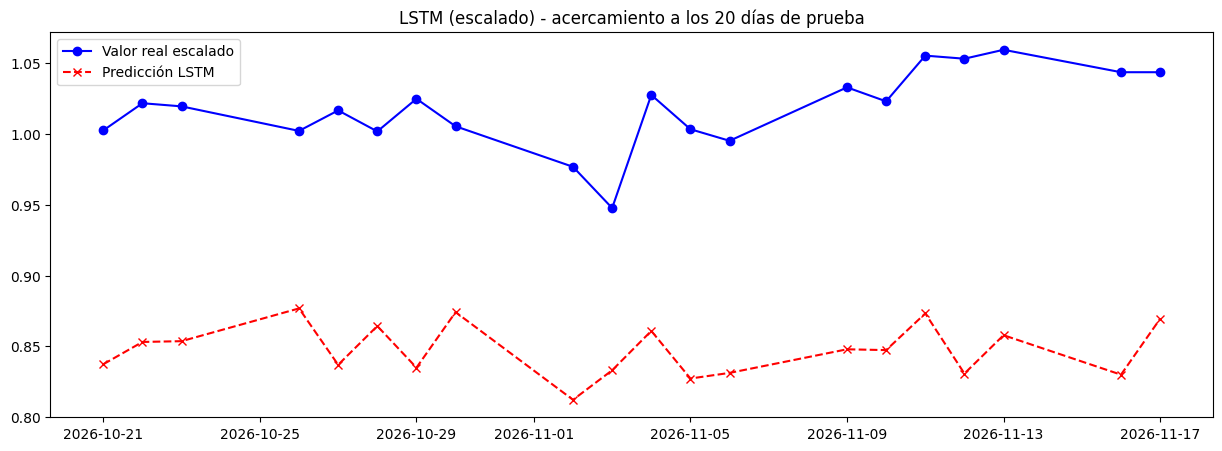

In [92]:
# (mejora) Acercamiento a los 20 días de prueba (datos escalados):
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test_escalado['ds'], test_escalado['y'], '-ob', label='Valor real escalado')
ax.plot(test_escalado['ds'], pred_LSTM_escalado, '--xr', label='Predicción LSTM')
ax.set_title('LSTM (escalado) - acercamiento a los 20 días de prueba')
ax.legend()
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en Datos Originales**

-----------------------------------------------------------------------------

* El LSTM con datos escalados obtuvo un **RMSE de 0.172**, que en dólares equivale a ≈38, mucho peor que con datos originales (14.453).
* Las predicciones quedan entre 0.81 y 0.88, muy abajo de los valores reales (0.95 a 1.06).
* En la curva de aprendizaje el error de validación sigue bajando en la época 200, es decir, el modelo todavía no terminaba de aprender; le faltaron épocas.
* Además, los valores de prueba son mayores a 1 (fuera del rango con el que se entrenó), y eso le cuesta trabajo al LSTM.

-----------------------------------------------------------------------------

# **CONCLUSIÓN DE LA ACTIVIDAD**


-----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**

En este caso, **el escalamiento no mejoró las predicciones de forma general**. Solo ayudó un poco a Prophet; a Ingenuo y ARIMA no les cambió nada y al LSTM lo empeoró. Los RMSE escalados se ven más pequeños porque están en una escala de 0 a 1. Para compararlos con los originales hay que multiplicarlos por el rango del precio (≈220.5 dólares).

### **Modelo Ingenuo**
No cambia. El modelo solo repite el valor anterior, así que el error es el mismo (0.026 ≈ 5.8 dólares contra 5.826).

### **Modelo ARIMA**
No cambia (0.027 ≈ 5.9 dólares contra 5.898), porque es un modelo lineal y escalar solo cambia las unidades.

### **Modelo Facebook-Meta-Prophet**
Mejoró un poco (0.031 ≈ 6.8 dólares contra 7.823). Sus parámetros de flexibilidad se ajustaron mejor con los datos entre 0 y 1.

### **Modelo Long Short Term Memory (LSTM)**
Empeoró (0.172 ≈ 38 dólares contra 14.453). En teoría el escalamiento ayuda a las redes neuronales, pero aquí el modelo necesitaba más épocas y los datos de prueba quedaron fuera del rango 0-1 del entrenamiento.

A continación se muestra una tabla comparativa con los valores RMSE de datos originales y datos escalados de cada uno de los modelos:


| # | Modelo  | Datos Originales RMSE | Datos Escalados RMSE |
|---|---------|-----------------------|----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 5.826 | 0.026 |
| 2 | Modelo ARIMA | 5.898 | 0.027 |
| 3 | Modelo Facebook-Meta-Prophet | 7.823 | 0.031 |
| 4 | Long Short Term Memory (LSTM) | 14.453 | 0.172 |

-----------------------------------------------------------------------------
# **INTERPRETACION de resultados RMSE**


### **RMSE DATOS ORIGINALES**

El mejor modelo fue el ingenuo (5.826), seguido muy de cerca por ARIMA (5.898); ambos se equivocan en promedio menos de 6 dólares por día. Después quedaron Prophet (7.823) y, al final, el LSTM (14.453).

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

### **RMSE DATOS ESCALADOS**

El orden se mantiene: Ingenuo (0.026), ARIMA (0.027), Prophet (0.031) y LSTM (0.172). La diferencia entre Prophet y los dos primeros se hizo más pequeña, mientras que el LSTM se alejó más.

+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **En conclusión:**

Para predecir el precio de la acción de Apple día con día, los modelos más simples (Ingenuo y ARIMA) dieron los mejores resultados. El precio de mañana suele estar muy cerca del de hoy y los cambios diarios son difíciles de anticipar. Prophet es útil para ver la tendencia general, y el LSTM necesitaría más datos, más épocas y probar otras arquitecturas para competir. El escalamiento no cambia los modelos lineales; solo puede ayudar a modelos como Prophet o redes neuronales, según cómo se ajusten.

-----------------------------------------------------------------------------

# **Referencias Bibliográficas**

Norton, V. (2011). Adjusted closing prices. arXiv preprint arXiv:1105.2956.

Luo, Y. X., & Ji, Y. (2022, September). Prediction of the Stock Adjusted Closing Price Based On Improved PSO-LSTM Neural Network. In 2022 International Conference on Machine Learning and Cybernetics (ICMLC) (pp. 43-48). IEEE.

Wijaya, A. C., Kusumaningrum, R., Sugiharto, A., & Aryotejo, G. (2024, July). Prophet Algorithm Optimization with Particle Swarm Optimization for Adjusted Closing Price Forecasting in Xiaomi Corporation. In 2024 7th International Conference on Informatics and Computational Sciences (ICICoS) (pp. 376-381). IEEE.


-----------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**